In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

# Jupyter may start the kernel in the repository root or in notebooks/.
PROJECT_ROOT = Path.cwd() if Path("data").is_dir() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


In [ ]:
import matplotlib.pyplot as plt
import random
import math
import seaborn as sns

# **Prédicteur Naif Bayes**




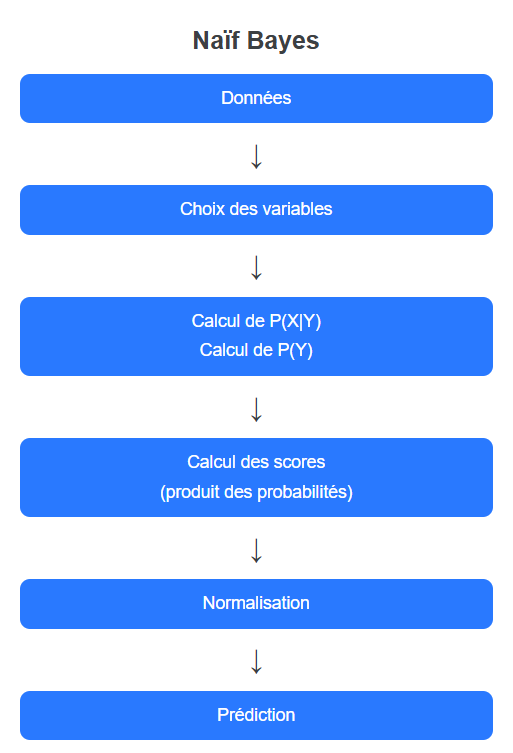

In [ ]:
data=pd.read_csv(DATA_DIR / "train.csv",index_col="Id")
prev_data=pd.read_csv(DATA_DIR / "prev.csv",index_col="Id")
data.head()

In [ ]:
def naif_bayes1 (train,test,va1):
    # Fonction qui prédit la classe pour UNE valeur de va1

    labels=train["espece"].unique()  # On récupère toutes les classes possibles (ex: Adelie, Gentoo, Chinstrap)
    
    pY= train["espece"].value_counts(normalize=True)  
    # Probabilité de chaque classe P(Y)
    # (fréquence de chaque espèce dans le dataset)
    
    pX1Y= pd.crosstab(train["espece"],train[va1],normalize="index")
    # Tableau des probabilités conditionnelles P(X1 | Y)
    # Pour chaque espèce, on calcule la distribution des valeurs de va1

    
    def naif_classif(va1):
        # Fonction qui prédit la classe pour UNE valeur de va1
        
        pred_y = pd.Series(index=labels) # On crée une série vide pour stocker les scores pour chaque classe
        for e in labels:
            pred_y[e]=pX1Y.loc[e,va1]*pY[e]
            # On applique la formule de Bayes simplifiée :
            # P(Y=e | X1=va1) ∝ P(X1=va1 | Y=e) * P(Y=e)
            
        return pred_y.idxmax() # On retourne la classe avec la probabilité maximale
        
    pred_y_table = pd.DataFrame(test,columns=["espece"]) # On crée un DataFrame pour stocker les prédictions
    
    pred_y_table["espece"]=test.apply(lambda ligne: naif_classif(ligne[va1]), axis=1) 
    # Pour chaque ligne du test :
    # - on prend la valeur de va1
    # - on applique la classification Naive Bayes
    # - axis=1 → ligne par ligne
    
    return pred_y_table # On retourne le tableau des prédictions

In [ ]:
def naif_bayes2 (train,test,v1,v2):
    # Fonction qui prédit la classe pour DEUX valeurs de v1 et v2
    
    labels=train["espece"].unique()
    pY= train["espece"].value_counts(normalize=True)
    pX1Y= pd.crosstab(train["espece"],train[v1],normalize="index")
    pX2Y= pd.crosstab(train["espece"],train[v2],normalize="index")
    
    def naif_classif(va1,va2):
        pred_y = pd.Series(index=labels)
        for e in labels:
            pred_y[e]=pX1Y.loc[e,va1]*pX2Y.loc[e,va2]*pY[e]
        return pred_y.idxmax()
        
    pred_y_table = pd.DataFrame(test,columns=["espece"])
    pred_y_table["espece"]=test.apply(lambda ligne: naif_classif(ligne[v1],ligne[v2]), axis=1)
    
    return pred_y_table

In [ ]:
def naif_bayes3(train,test,v1,v2,v3):
    # Fonction qui prédit la classe pour TROIS valeurs de v1, v2 et v3
    
    labels=train["espece"].unique()
    pY= train["espece"].value_counts(normalize=True)
    pX1Y= pd.crosstab(train["espece"],train[v1],normalize="index")
    pX2Y= pd.crosstab(train["espece"],train[v2],normalize="index")
    pX3Y= pd.crosstab(train["espece"],train[v3],normalize="index")
    
    def naif_classif(va1,va2, va3,):
        pred_y = pd.Series(index=labels)
        for e in labels:
            pred_y[e]=pX1Y.loc[e,va1]*pX2Y.loc[e,va2]*pX3Y.loc[e,va3]*pY[e]
        return pred_y.idxmax()
        
    pred_y_table = pd.DataFrame(test,columns=["espece"])
    pred_y_table["espece"]=test.apply(lambda ligne: naif_classif(ligne[v1],ligne[v2],ligne[v3]), axis=1)
    
    return pred_y_table

In [ ]:
def naif_bayes4(train,test,v1,v2,v3,v4):
    # Fonction qui prédit la classe pour QUATRE valeurs de v1, v2, v3 et v4
    
    labels=train["espece"].unique()
    pY= train["espece"].value_counts(normalize=True)
    pX1Y= pd.crosstab(train["espece"],train[v1],normalize="index")
    pX2Y= pd.crosstab(train["espece"],train[v2],normalize="index")
    pX3Y= pd.crosstab(train["espece"],train[v3],normalize="index")
    pX4Y= pd.crosstab(train["espece"],train[v4],normalize="index")
    
    def naif_classif(va1,va2, va3, va4):
        pred_y = pd.Series(index=labels)
        for e in labels:
            pred_y[e]=pX1Y.loc[e,va1]*pX2Y.loc[e,va2]*pX3Y.loc[e,va3]*pX4Y.loc[e,va4]*pY[e]
        return pred_y.idxmax()
        
    pred_y_table = pd.DataFrame(test,columns=["espece"])
    pred_y_table["espece"]=test.apply(lambda ligne: naif_classif(ligne[v1],ligne[v2],ligne[v3],ligne[v4]), axis=1)
    return pred_y_table

In [ ]:
def classe_quartile(x,bornes,labels):
    # Fonction qui classe une valeur x dans un intervalle (quartile)
    
    if x <= bornes[0]:    
        return labels[0]
        # Si x est inférieur ou égal à la première borne → 1er quartile
    elif x <= bornes[1]:
        return labels[1]   
        # Si x est entre borne[0] et borne[1] → 2e quartile

    elif x <= bornes[2]:
        return labels[2]
        # Si x est entre borne[1] et borne[2] → 3e quartile
    else:
        return labels[3]
        # Sinon → 4e quartile (les plus grandes valeurs)
        

In [ ]:
def Acc(prev,true, v='espece'):
    return 100*(prev[v]==true[v]).mean()
df = data.copy()

In [ ]:
v="longueur_bec_mm"
bornes=[df[v].quantile(0.25),df[v].quantile(0.50),df[v].quantile(0.75)]
labels=["Q1","Q2","Q3","Q4"]
df["longueur_bec_mm_Q"]=df[v].apply(lambda x:classe_quartile(x,bornes,labels))
df["longueur_bec_mm_Q"]

In [ ]:
v="masse_g"
bornes=[df[v].quantile(0.25),df[v].quantile(0.50),df[v].quantile(0.75)]
labels=["Q1","Q2","Q3","Q4"]
df["masse_Q"]=df[v].apply(lambda x:classe_quartile(x,bornes,labels))
df["masse_Q"]

In [ ]:
v="longueur_nageoire_mm"
bornes=[df[v].quantile(0.25),df[v].quantile(0.50),df[v].quantile(0.75)]
labels=["Q1","Q2","Q3","Q4"]
df["longueur_nageoire_mm_Q"]=df[v].apply(lambda x:classe_quartile(x,bornes,labels))
df["longueur_nageoire_mm_Q"]

In [ ]:
v="epaisseur_bec_mm"
bornes=[df[v].quantile(0.25),df[v].quantile(0.50),df[v].quantile(0.75)]
labels=["Q1","Q2","Q3","Q4"]
df["epaisseur_bec_mm_Q"]=df[v].apply(lambda x:classe_quartile(x,bornes,labels))
df["epaisseur_bec_mm_Q"]

In [ ]:
df["masse_D"] = pd.qcut(df["masse_g"], 10, labels=False)
df["nageoire_D"] = pd.qcut(df["longueur_nageoire_mm"], 10, labels=False)
df["epaisseur_bec_mm_D"] = pd.qcut(df["epaisseur_bec_mm"], 10, labels=False)
df["longueur_bec_mm_D"] = pd.qcut(df["longueur_bec_mm"], 10, labels=False)

In [ ]:
df["masse_D"].value_counts(normalize=True)

In [ ]:
df["masse_Q"].value_counts(normalize=True)

In [ ]:
df["masse_g"].value_counts(normalize=True)

In [ ]:
pred=naif_bayes1(df,df,"masse_Q")
Acc(data,pred)

In [ ]:
pred=naif_bayes2(df,df,"epaisseur_bec_mm_Q","longueur_bec_mm_Q")
Acc(data,pred)

In [ ]:
pred=naif_bayes3(df,df,"epaisseur_bec_mm_Q","longueur_bec_mm_Q","longueur_nageoire_mm_Q")
Acc(data,pred)

In [ ]:
pred=naif_bayes4(df,df,"epaisseur_bec_mm_Q","longueur_bec_mm_Q","masse_Q","longueur_nageoire_mm_Q")
Acc(data,pred)

In [ ]:
data

In [ ]:
pred=naif_bayes1(df,df,"epaisseur_bec_mm_D")
Acc(data,pred)

In [ ]:
pred=naif_bayes2(df,df,"epaisseur_bec_mm_D","longueur_bec_mm_D")
Acc(data,pred)

In [ ]:
pred=naif_bayes3(df,df,"epaisseur_bec_mm_D","longueur_bec_mm_D","masse_D")
Acc(data,pred)

In [ ]:
pred=naif_bayes4(df,df,"epaisseur_bec_mm_D","longueur_bec_mm_D","masse_D","nageoire_D")
Acc(data,pred)

In [ ]:
# Créer la structure vide
comparaison = pd.DataFrame(
    index=["Bayes 1", "Bayes 2", "Bayes 3", "Bayes 4"],
    columns=["Variables", "4 quantiles", "10 quantiles"]
)

# Remplir la colonne "Variables" pour te souvenir quelles variables sont utilisées
comparaison["Variables"] = [
    "masse_g",
    "longueur_bec_mm + epaisseur_bec_mm",
    "longueur_bec_mm + epaisseur_bec_mm + longueur_nageoire_mm",
    "longueur_bec_mm + epaisseur_bec_mm + masse_g + longueur_nageoire_mm"
]

comparaison.loc["Bayes 1","4 quantiles"]=Acc(data,naif_bayes1(df,df,"masse_Q"))
comparaison.loc["Bayes 2","4 quantiles"]=Acc(data,naif_bayes2(df,df,"longueur_bec_mm_Q","epaisseur_bec_mm_Q"))
comparaison.loc["Bayes 3","4 quantiles"]=Acc(data,naif_bayes3(df,df,"longueur_bec_mm_Q","epaisseur_bec_mm_Q","longueur_nageoire_mm_Q"))
comparaison.loc["Bayes 4","4 quantiles"]=Acc(data,naif_bayes4(df,df,"masse_Q","longueur_bec_mm_Q","epaisseur_bec_mm_Q","longueur_nageoire_mm_Q"))

comparaison.loc["Bayes 1","10 quantiles"]=Acc(data,naif_bayes1(df,df,"epaisseur_bec_mm_D"))
comparaison.loc["Bayes 2","10 quantiles"]=Acc(data,naif_bayes2(df,df,"longueur_bec_mm_D","epaisseur_bec_mm_D"))
comparaison.loc["Bayes 3","10 quantiles"]=Acc(data,naif_bayes3(df,df,"longueur_bec_mm_D","epaisseur_bec_mm_D","nageoire_D"))
comparaison.loc["Bayes 4","10 quantiles"]=Acc(data,naif_bayes4(df,df,"masse_D","longueur_bec_mm_D","epaisseur_bec_mm_D","nageoire_D"))

# Afficher le tableau
comparaison

In [ ]:
da=data.copy()

In [ ]:
def Bayes2(train, prev, v1, v2):
    labels = train['espece'].unique()
    Py = train['espece'].value_counts(normalize=True)
    PxSy1 = pd.crosstab(train['espece'], train[v1], normalize=True)
    PxSy2 = pd.crosstab(train['espece'], train[v2], normalize=True)
    
    def classify(x): #prend une ligne du DataFrame prev, c’est-à-dire un pingouin.
        
        #On crée une série vide pour stocker le score de chaque espèce pour ce pingouin.
        s = pd.Series(index=labels) 
        for y in labels:
                  # Px1/Y=y               #Px2/Y=y              #PY(y)
            #on calcule les probas que chaque variable prend une telle valeur pour chaque espece y
            s[y] = PxSy1.loc[y, x[v1]] * PxSy2.loc[y, x[v2]] * Py[y]
        return s.idxmax()
    
    return pd.DataFrame({'espece': prev.apply(classify, axis=1)})

In [ ]:
pred = Bayes2(da, da, 'masse_g', 'longueur_bec_mm')   #<-- le meilleur couple de predicteurs
Acc(pred, da)

# Classificateur de Bayes - loi normale

***Théorème de Bayes***

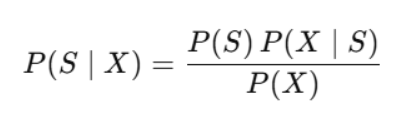

***Formule - loi normale***

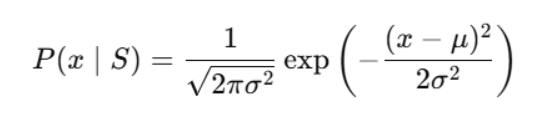

In [ ]:
def loi_normale(x, moyenne, var):
    eps = 1e-6
    coeff = 1 / np.sqrt(2 * np.pi * (var + eps))
    exponent = np.exp(-((x - moyenne)**2) / (2 * (var + eps)))
    return coeff * exponent

In [ ]:
dfj= data.copy()
dfj.head()

In [ ]:
priors = dfj["espece"].value_counts(normalize=True)
priors


 # Création de nouvelles variables utiles

Les caractéristiques brutes mesurent la taille.

Les ratios mesurent la forme.

Les différences entre espèces concernent souvent la forme, et pas seulement la taille.

*C’est pourquoi les ratios permettent une meilleure distinction des classes.*


In [ ]:
dfj['proportion_bec']=(dfj.longueur_bec_mm)/(dfj.epaisseur_bec_mm)
dfj.head(5)

In [ ]:
dfj['masse_nageoire_proportion'] = dfj.masse_g / dfj.longueur_nageoire_mm
dfj.head(5)

1. **Créez une liste contenant toutes les variables que nous souhaitons prendre en compte.**

In [ ]:
features = [
    "longueur_bec_mm",
    "epaisseur_bec_mm",
    "longueur_nageoire_mm",
    "masse_g",
    "masse_nageoire_proportion",
    "proportion_bec" 
]

In [ ]:
grouped = dfj.groupby("espece")

In [ ]:
means = grouped[features].mean()
variances = grouped[features].var()

In [ ]:
means

In [ ]:
variances

In [ ]:
def predire_une(ligne):
    posteriors = {} #contient les probabilites pour chaque espece

    for espece in priors.index: #On parcourt chaque classe possible (Adelie, Gentoo, etc.)

        prior = priors[espece] #Probabilité de base de l’espèce: P(Y)
        vraiesemblance = 1 #On initialise la vraisemblance

        for feature in features: # On parcourt toutes les variables (longueur_bec, masse, etc.)
            mean = means.loc[espece, feature] #Ensortir la moyenne de la variable pour l'espece en question 
            
            var = variances.loc[espece, feature] #Ensortir la varience
            
            x = ligne[feature] # Valeur réelle de la variable pour l’individu à prédire

            vraiesemblance *= loi_normale(x, mean, var)

        posteriors[espece] = prior * vraiesemblance
        
    return max(posteriors, key=posteriors.get) #On choisit l’espèce avec la plus grande probabilité


In [ ]:
dfj["predictions"] = dfj.apply(predire_une, axis=1)
dfj.head(5)

In [ ]:
prob_error = (dfj["predictions"] != dfj["espece"]).mean()

In [ ]:
print("Probabilité d'erreur:", prob_error)
print("Accuracy:", 1 - prob_error)

In [ ]:
ds=df["espece"]
ds

In [ ]:
pred=naif_bayes2(data,prev_data,"ile_origine","sexe")
pred

In [ ]:
ds=pred['espece']
ds

In [ ]:
ds.to_csv(OUTPUT_DIR / "submission.csv", index=True, index_label="Id")

In [ ]:
ds